# T1: Loading and describing the evolving TKH

This notebook covers task T1: per-snapshot node and edge counts, node types, hyper-edge arity, time span, growth between snapshots, and data-quality problems. The computation lives in `tkh/io.py` and `tkh/describe.py`, and this notebook only calls it and plots the results.

**Inputs** come from the run configuration (`tkh/config.py`): `configs/default.toml`, or the file named by the `TKH_CONFIG` environment variable. For example:

```bash
TKH_CONFIG=/path/to/my.toml jupyter nbconvert --to notebook --execute --inplace notebooks/01_describe_graph.ipynb
```

All tables and figures are recomputed from the configured inputs. The commentary in the text cells describes the provided export (Option A of §4, `data/tkh_collection10.json`: 52 papers on ML for materials science, 2013–2026). With other inputs, read the commentary against the recomputed outputs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, MaxNLocator, NullFormatter, ScalarFormatter
import pandas as pd

from tkh.config import load_config
from tkh.io import load, make_snapshots
from tkh import describe as d

MPL = tuple(int(x) for x in matplotlib.__version__.split(".")[:2])
print(f"python {sys.version.split()[0]}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

cfg = load_config()  # honours $TKH_CONFIG
CUTOFFS = cfg.cutoffs
FIG = cfg.figures_dir
FIG.mkdir(parents=True, exist_ok=True)
print(f"config: {cfg.source}\ngraph: {cfg.graph}\narticles: {cfg.articles or '(derived from graph)'}\nfigures -> {FIG}")

tkh = load(cfg)
snaps = make_snapshots(tkh, CUTOFFS)
print(f"{len(tkh.nodes)} nodes, {len(tkh.edges)} hyper-edges, {len(tkh.articles)} articles; "
      f"export {tkh.meta.get('exported_at', 'n/a')}; cutoffs {CUTOFFS}")

python 3.12.11, pandas 3.0.6, matplotlib 3.11.2
config: /Users/alexeyr/Personal/TKH/repo/configs/default.toml
graph: /Users/alexeyr/Personal/TKH/repo/data/tkh_collection10.json
articles: /Users/alexeyr/Personal/TKH/repo/data/collection10_articles.csv
figures -> /Users/alexeyr/Personal/TKH/repo/figures
5798 nodes, 1429 hyper-edges, 52 articles; export 2026-08-15T11:09:59+00:00; cutoffs (2020, 2022, 2024, 2026)


## 1. What the data looks like: one paper as an illustrative unit

The export is a list of **nodes** (entities such as methods, datasets and tasks) and a list of **hyper-edges**, each connecting two or more nodes. Every hyper-edge comes from exactly one paper: `provenance.article_id`.

To show what a unit of each entity type and each relation looks like, this section walks through one paper. The paper is chosen by code: the one whose hyper-edges cover the most relation types and node types, with ties going to the smallest. The statistics in later sections describe the whole collection of such papers.

In [2]:
A = d.example_article(tkh)
print(f"example article {A}: " + "; ".join(f"{k} = {v}" for k, v in tkh.articles.loc[A].items()))
print(f"{len(d.article_nodes(tkh, A))} nodes and {int((tkh.edges['article_id'] == A).sum())} hyper-edges come from this paper")

example article 5397: year = 2019; arxiv_id = 1812.05055; status = COMPLETED; title = Graph Networks as a Universal Machine Learning Framework for Molecules and Crystals; node_id = arti_00021
58 nodes and 20 hyper-edges come from this paper


**Raw records.** Below are one node and one hyper-edge exactly as they appear in the input JSON:
- the node is the method the paper presents;
- the hyper-edge is its richest `evaluated_on` (or otherwise first) edge.

Some columns in the tables further down are added by `tkh/io.py`:
- `entry_year`, the snapshot key from §2;
- `n_articles`, the number of papers a node appears in.

In [3]:
import json
raw = json.loads(cfg.graph.read_text())
raw_nodes = {str(n["id"]): n for n in raw["nodes"]}
raw_edges = {str(e["id"]): e for e in raw["hyperedges"]}
rel = d.relation_examples(tkh, A)
present = rel.loc["presents", "edge_id"] if "presents" in rel.index else None
method_id = raw_edges[present]["members"][1] if present else raw_edges[rel["edge_id"].iloc[0]]["members"][0]
edge_id = rel.loc["evaluated_on", "edge_id"] if "evaluated_on" in rel.index else rel["edge_id"].iloc[0]
print("node:\n" + json.dumps(raw_nodes[str(method_id)], indent=1, ensure_ascii=False))
print("\nhyper-edge:\n" + json.dumps(raw_edges[str(edge_id)], indent=1, ensure_ascii=False))

node:
{
 "id": "meth_00057",
 "type": "method",
 "surface_form": "Materials Graph Network",
 "year": 2019,
 "origin_year": 2019,
 "first_seen_year": 2019,
 "last_seen_year": 2025,
 "provenance": {
  "source": "mvkg",
  "collection_id": 10,
  "articles": [
   5397,
   5445,
   5449,
   5453
  ],
  "entity_id": 182747
 },
 "aliases": [
  "MEGNet"
 ]
}

hyper-edge:
{
 "id": "h_00493",
 "relation_type": "evaluated_on",
 "members": [
  "meth_00057",
  "data_00089",
  "metr_00002"
 ],
 "year": 2019,
 "provenance": {
  "source": "mvkg",
  "article_id": 5397,
  "article_year": 2019
 },
 "attributes": {
  "task": "Regression",
  "domain": "Materials Science",
  "metric": "MAE",
  "value": 0.024
 }
}


**Nodes: one example per type, taken from this paper.**
- **Preference:** where possible, the example is a node shared with other papers but not a generic hub, so that cross-paper sharing is visible.
- **`surface_form`** is the node's name as extracted.
- **Year fields:**
  - `origin_year` is known for articles, cited works and some methods;
  - `first_seen_year` / `last_seen_year` span the papers that mention the node;
  - `entry_year` is the snapshot key.
- **`nodes_of_this_type`** gives the size of that type across the whole collection.

In [4]:
d.node_examples(tkh, A)

,type,surface_form,year,origin_year,first_seen_year,last_seen_year,entry_year,n_articles,entity_id,nodes_of_this_type
id,,,,,,,,,,
tech_00084,technique,Set2Set pooling,2017,<NA>,2017,2019,2017,2,199080,962
comp_00018,component,Set2Set readout,2017,<NA>,2017,2019,2017,2,180473,855
task_00001,task,machine learning,2017,<NA>,2017,2022,2017,7,2100,732
clai_00488,claim,MEGNet models achieve lower mean absolute erro...,2019,<NA>,2019,2019,2019,1,<NA>,690
prob_00161,problem,Interpretability of learned chemical trends,2019,<NA>,2019,2019,2019,1,247315,634
cite_00092,cited_work,Wang et al.,2018,2018,2019,2026,2019,2,<NA>,580
meth_00050,method,SchNet,2017,2017,2017,2024,2017,7,180527,448
auth_00115,author,Shyue Ping Ong,2013,<NA>,2013,2025,2013,4,246856,318
data_00089,dataset,Materials Project formation energy,2019,<NA>,2019,2019,2019,1,247329,259


**Relations: one example hyper-edge per relation type, taken from this paper.**
- **Hub.** `members[0]` is always the hub: either the article itself or the method it presents (§5). The other members are the paper's targets for that relation.
- **Attributes.** Only `claims` and `evaluated_on` carry descriptive attributes: claim type, evidence and confidence, or metric, value and split. They are also the only relations that occur more than once per paper.

In [5]:
rel

,edge_id,edges_in_article,arity,hub (members[0]),other members,attributes
relation_type,,,,,,
authored_by,h_01354,1,6,Graph Networks as a Universal Machine Le [arti...,Chi Chen [author]; Shyue Ping Ong [author]; We...,-
cites,h_01310,1,9,Graph Networks as a Universal Machine Le [arti...,Pettifor [cited_work]; Xie & Grossman [cited_w...,-
claims,h_01094,9,2,Graph Networks as a Universal Machine Le [arti...,MEGNet models achieve lower mean absolut [claim],"claim_type=comparative, evidence_type=simulati..."
presents,h_00325,1,2,Graph Networks as a Universal Machine Le [arti...,Materials Graph Network [method],-
proposes_future_work,h_01403,1,6,Graph Networks as a Universal Machine Le [arti...,Unified free‑energy MEGNet model incorpo [futu...,-
addresses,h_00112,1,7,Materials Graph Network [method],Molecule property prediction [task]; Crystal p...,-
evaluated_on,h_00493,2,3,Materials Graph Network [method],Materials Project formation energy [dataset]; ...,"task=Regression, domain=Materials Science, met..."
extends,h_00114,1,5,Materials Graph Network [method],SchNet [method]; Message Passing Neural Networ...,-
solves,h_00115,1,5,Materials Graph Network [method],Lack of a unified framework for molecule [prob...,-


**Figure 1.1. The paper as a star.**
- **Centre.** The article node, and the method it presents.
- **Boxes.** Each box is one relation type, attached to its hub. It gives the number of hyper-edges, the number and types of distinct target nodes, and a few example targets.

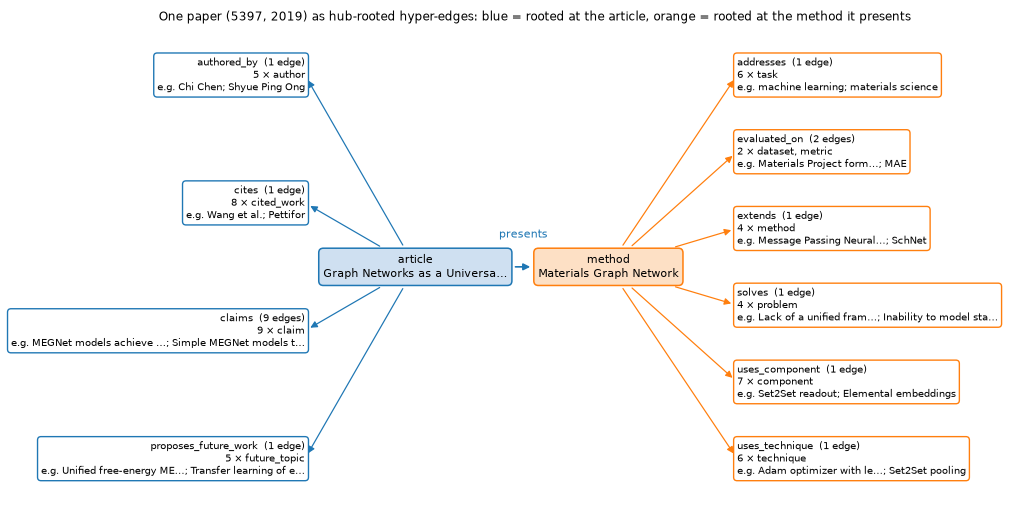

In [6]:
star = d.article_star(tkh, A)
left = star[star["hub_type"] == "article"].drop(index="presents", errors="ignore")
right = star[star["hub_type"] != "article"]
HCOL = {"article": "C0", "method": "C1"}
AX, MX, LX, RX = -0.6, 3.6, -3.0, 6.4  # article / method centres; inner edges of left / right box columns

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.set(xlim=(-8.2, 12.2), ylim=(-3.4, 3.4)); ax.axis("off")
title = tkh.articles.at[A, "title"] if "title" in tkh.articles else str(A)
hubs = {"article": ax.text(AX, 0, "article\n" + title[:28] + ("…" if len(title) > 28 else ""), ha="center", va="center",
                           fontsize=7.5, bbox=dict(boxstyle="round,pad=0.4", fc="#cfe0f1", ec="C0"))}
if "presents" in star.index:
    hubs["method"] = ax.text(MX, 0, "method\n" + star.loc["presents", "examples"][0][:28], ha="center", va="center",
                             fontsize=7.5, bbox=dict(boxstyle="round,pad=0.4", fc="#fde0c5", ec="C1"))
    ax.annotate("", xy=(MX, 0), xytext=(AX, 0), arrowprops=dict(arrowstyle="-|>", color="C0", lw=1.1,
                patchA=hubs["article"].get_bbox_patch(), patchB=hubs["method"].get_bbox_patch()))
    ax.text((AX + MX) / 2 + 0.25, 0.42, "presents", fontsize=7, color="C0", ha="center")

def box(x, y, rel, row, ha):
    ex = "; ".join(e[:22] + ("…" if len(e) > 22 else "") for e in row["examples"][:2])
    txt = (f"{rel}  ({row['edges']} edge{'s' if row['edges'] > 1 else ''})\n"
           f"{row['targets']} × {row['target_types']}\ne.g. {ex}")
    return ax.text(x, y, txt, ha=ha, va="center", fontsize=6.5,
                   bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=HCOL.get(row["hub_type"], "0.5"), lw=0.9))

for side, x_edge, ha in ((left, LX, "right"), (right, RX, "left")):
    ys = [2.75 - 5.5 * i / max(len(side) - 1, 1) for i in range(len(side))]
    for (rel, row), y in zip(side.iterrows(), ys):
        hub = hubs.get(row["hub_type"], hubs.get("method", hubs["article"]))
        box(x_edge, y, rel, row, ha)
        ax.annotate("", xy=(x_edge, y), xytext=hub.get_position(),
                    arrowprops=dict(arrowstyle="-|>", color=HCOL.get(row["hub_type"], "0.5"), lw=0.8,
                                    patchA=hub.get_bbox_patch(), shrinkA=2, shrinkB=4))
ax.set_title(f"One paper ({A}, {tkh.articles.at[A, 'year']}) as hub-rooted hyper-edges: "
             f"blue = rooted at the article, orange = rooted at the method it presents", fontsize=8)
fig.savefig(FIG / "t1_example_article.png"); plt.show()

In [7]:
apn_all = tkh.nodes.loc[d.article_nodes(tkh, A), "prov_articles"].map(len)
print(f"{(apn_all == 1).mean():.0%} of this paper's nodes appear in no other paper; "
      f"{(apn_all > 1).sum()} are shared, e.g. "
      + ", ".join(tkh.nodes.loc[apn_all.sort_values(ascending=False).index[:6], "surface_form"]))

76% of this paper's nodes appear in no other paper; 14 are shared, e.g. materials science, MAE, SchNet, machine learning, Message Passing Neural Network, crystal graph convolutional neural networks


What this unit implies for the rest of the analysis:
- **Membership means role.** Most hyper-edges are bundles: "the components / techniques / problems / cited works of this one paper". Being in the same hyper-edge usually means "same paper, same role", not a measured n-ary relation. Only `claims` and `evaluated_on` are finer-grained.
- **Papers connect through shared nodes.** Most of a paper's nodes appear in that paper only. Papers are linked through the few nodes that recur, such as well-known methods, metrics and generic tasks (§6, §7).
- **Two hubs per paper.** Each paper has two hubs, the article and its presented method. That is why §5 finds every edge rooted at one of them.

## 2. Snapshot definition

The export carries several year fields (`meta.date_semantics`). Only one of them is safe to use for cutting snapshots.

- **Hyper-edge**: in snapshot *c* iff `provenance.article_year ≤ c`, i.e. the paper asserting it was published by *c*.
- **Node**: its entry year is the earliest publication year over its `provenance.articles` and the articles of its incident edges. It is in snapshot *c* iff entry year ≤ *c*. The second source is needed because 36 memberships list a node whose provenance omits the edge's article (§7).

The alternatives leak content from later papers. The table below counts the extra nodes and edges each alternative would admit beyond the chosen rule:
- `first_seen_year` contradicts its documented meaning for 127 nodes;
- `node.year` is the origin year, e.g. PCA 1901;
- `edge.year` is the year of the result row, not of the asserting paper.

In [8]:
d.key_leakage(tkh, CUTOFFS)

,nodes (chosen),extra nodes via node.first_seen_year,extra nodes via node.year,edges (chosen),extra edges via edge.year
cutoff,,,,,
2020,1475,30,364,374,31
2022,2144,27,357,554,42
2024,4094,70,213,983,80
2026,5798,0,0,1429,0


**Cutoffs**: ≤2020, ≤2022, ≤2024, ≤2026.
- They include the brief's example cutoffs and add ≤2026, so all 52 papers are used. The brief's three cutoffs alone would leave out about 29% of nodes.
- This gives three transitions for cross-snapshot stability.
- Before 2020 the corpus is too small (≤2019 has 12 papers).

**Assumptions:**
- `year` is the venue publication year. For 10 of the 36 arXiv papers the preprint is 1–2 years older.
- The ≤2026 snapshot covers 2026 only up to the export date (2026-08-15).
- Ingestion timestamps (`ingested_at`, all from 2026) are pipeline dates and play no role here.

In [9]:
closure = {s.cutoff: sum(v not in s.node_ids for m in s.edges["members"] for v in m) for s in snaps}
assert all(v == 0 for v in closure.values()), closure
print("edge members outside their snapshot's node set:", closure)

edge members outside their snapshot's node set: {2020: 0, 2022: 0, 2024: 0, 2026: 0}


## 3. Size and time span per snapshot

In [10]:
summary = d.snapshot_summary(tkh, snaps)
summary

,articles,nodes,hyperedges,incidences,first_year,last_year,components,largest_component_share
snapshot,,,,,,,,
<=2020,16,1475,374,2084,2013,2020,1,1.000
<=2022,22,2144,554,3149,2013,2022,1,1.000
<=2024,38,4094,983,6084,2013,2024,2,0.994
<=2026,52,5798,1429,8929,2013,2026,2,0.996


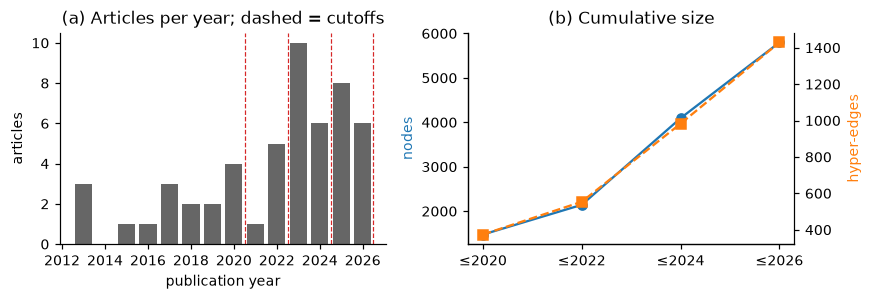

In [11]:
years = tkh.articles["year"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].bar(years.index, years.values, color="0.4")
for c in CUTOFFS:
    ax[0].axvline(c + 0.5, color="C3", lw=0.8, ls="--")
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set(xlabel="publication year", ylabel="articles", title="(a) Articles per year; dashed = cutoffs")
x = [f"≤{c}" for c in CUTOFFS]
ax[1].plot(x, summary["nodes"], "o-", color="C0")
ax[1].set_ylabel("nodes", color="C0")
ax2 = ax[1].twinx()
ax2.plot(x, summary["hyperedges"], "s--", color="C1")
ax2.set_ylabel("hyper-edges", color="C1"); ax2.spines["right"].set_visible(True)
ax[1].set(title="(b) Cumulative size")
fig.tight_layout()
fig.savefig(FIG / "t1_size_over_time.png"); plt.show()

The corpus is back-loaded: 30 of the 52 papers are from 2023–2026. From ≤2024 the hypergraph has a second component of 24 nodes. That is article 5405, which has no method-rooted edges (§7).

## 4. Node and relation types

In [12]:
types = d.node_type_counts(tkh, snaps)
types

,<=2020,<=2022,<=2024,<=2026
type,,,,
technique,247,345,673,962
component,221,309,608,855
task,197,263,517,732
claim,179,246,445,690
problem,146,198,415,634
cited_work,114,214,411,580
method,129,191,352,448
author,105,131,250,318
dataset,56,121,200,259


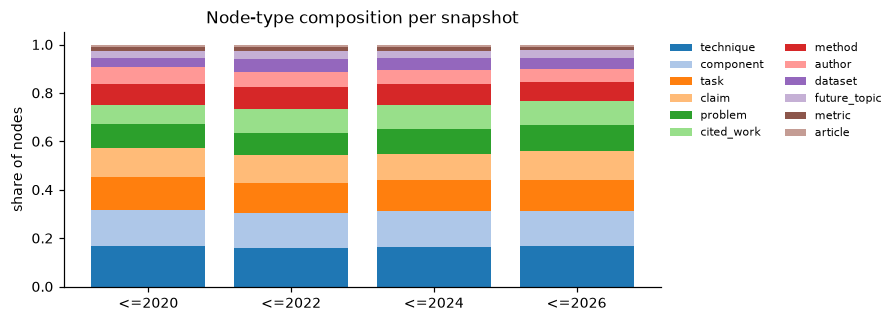

In [13]:
share = types / types.sum()
fig, ax = plt.subplots(figsize=(7, 3))
bottom = pd.Series(0.0, index=share.columns)
for i, (t, row) in enumerate(share.iterrows()):
    ax.bar(share.columns, row, bottom=bottom, label=t, color=plt.cm.tab20(i))
    bottom += row
ax.set(ylabel="share of nodes", title="Node-type composition per snapshot")
ax.legend(ncol=2, fontsize=7, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
fig.savefig(FIG / "t1_node_types.png"); plt.show()

In [14]:
d.relation_type_counts(snaps)

,<=2020,<=2022,<=2024,<=2026
relation_type,,,,
claims,179,246,445,690
evaluated_on,61,121,221,301
presents,16,22,38,52
addresses,16,22,37,51
authored_by,16,22,38,51
solves,16,22,37,51
uses_technique,16,22,37,51
extends,16,22,37,50
uses_component,16,22,37,50


## 5. Hyper-edge arity

In [15]:
d.arity_summary(snaps)

,mean,median,max,share_2,share_3,share_ge_10
snapshot,,,,,,
<=2020,5.572,3.0,45,0.291,0.404,0.147
<=2022,5.684,3.0,59,0.253,0.453,0.148
<=2024,6.189,3.0,65,0.214,0.495,0.161
<=2026,6.248,3.0,65,0.195,0.526,0.160


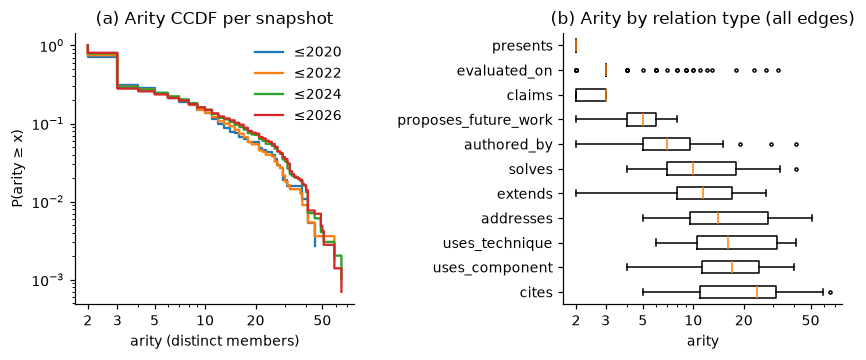

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"wspace": 0.75})
for s in snaps:
    a = s.edges["arity"].sort_values()
    ax[0].step(a, 1 - (pd.Series(range(len(a))) / len(a)).values, where="post", label=f"≤{s.cutoff}")
ax[0].set(xscale="log", yscale="log", xlabel="arity (distinct members)", ylabel="P(arity ≥ x)",
          title="(a) Arity CCDF per snapshot")
ax[0].legend(frameon=False)
byrel = d.arity_by_relation(tkh.edges).index
# 'orientation' exists from matplotlib 3.10, where 'vert' is deprecated; support both
horizontal = {"orientation": "horizontal"} if MPL >= (3, 10) else {"vert": False}
ax[1].boxplot([tkh.edges.loc[tkh.edges["relation_type"] == r, "arity"] for r in byrel],
              flierprops={"markersize": 2}, **horizontal)
ax[1].set_yticks(range(1, len(byrel) + 1), byrel)
ax[1].set(xscale="log", xlabel="arity", title="(b) Arity by relation type (all edges)")
for a in ax:
    a.xaxis.set_major_locator(FixedLocator([2, 3, 5, 10, 20, 50]))
    a.xaxis.set_major_formatter(ScalarFormatter()); a.xaxis.set_minor_formatter(NullFormatter())
fig.savefig(FIG / "t1_arity.png"); plt.show()

In [17]:
d.arity_by_relation(tkh.edges)

,edges,min,median,max
relation_type,,,,
cites,37,5,24.0,65
uses_component,50,4,17.0,40
uses_technique,51,6,16.0,41
addresses,51,5,14.0,51
extends,50,2,11.5,27
solves,51,4,10.0,41
authored_by,51,2,7.0,41
proposes_future_work,45,2,5.0,8
claims,690,2,3.0,3


Every hyper-edge is a **hub-rooted star**. `members[0]` is either the article or the method the article presents (table below), and the remaining members are that paper's typed targets: tasks, techniques, components, cited works and so on.
- `claims` (arity 2–3) and `evaluated_on` (median 3) are the only relations that occur several times per paper.
- Each of the other relations occurs at most once per paper, as one bundle of that paper's mentions.
- So a large arity mostly means "mentioned together in one paper", not an n-ary scientific fact. This matters for the T4 coarsening rule.

In [18]:
d.hub_positions(tkh, tkh.edges)

members,article,method
relation_type,,
addresses,0,51
authored_by,51,0
cites,37,0
claims,690,0
evaluated_on,0,301
extends,0,50
presents,52,0
proposes_future_work,45,0
solves,0,51


In [19]:
pairs = d.clique_vs_star_pairs(tkh.edges)
print(pairs, f"-> clique expansion inflates pairs {pairs['clique_pairs'] / pairs['star_pairs']:.1f}x over the star view")

{'clique_pairs': 70022, 'star_pairs': 6661, 'incidences': 8929} -> clique expansion inflates pairs 10.5x over the star view


## 6. Growth and change between snapshots

In [20]:
g = d.growth(tkh, snaps)
g.T

transition,<=2020 -> <=2022,<=2022 -> <=2024,<=2024 -> <=2026
new_articles,6.000,16.000,14.000
new_nodes,669.000,1950.000,1704.000
node_growth,0.454,0.910,0.416
new_edges,180.000,429.000,446.000
edge_growth,0.481,0.774,0.454
node_jaccard,0.688,0.524,0.706
new_edges_touching_old_nodes,0.183,0.189,0.200
old_nodes_mentioned_again,0.043,0.068,0.046
new_nodes_sharing_edge_with_old,0.502,0.485,0.498
removed_nodes,0.000,0.000,0.000


**Figure 6.1. Cumulative layers.** Each bar is one snapshot, split by the period in which its nodes (or hyper-edges) entered. Every earlier layer persists unchanged into later snapshots: the graph only accretes.

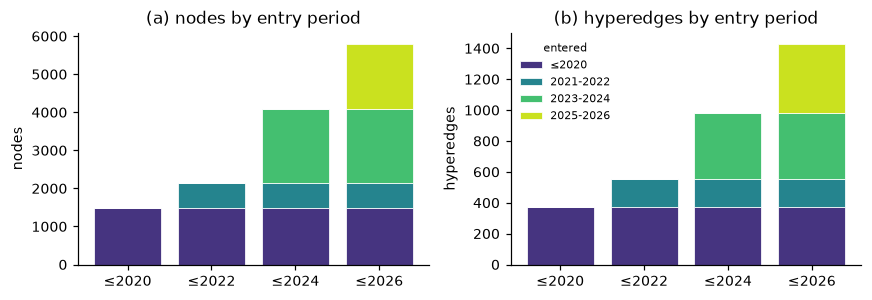

In [21]:
PERIODS = d.period_labels(list(CUTOFFS))
PCOL = dict(zip(PERIODS, plt.cm.viridis([0.15, 0.45, 0.7, 0.92][:len(PERIODS)] if len(PERIODS) <= 4
                                       else [i / (len(PERIODS) - 1) for i in range(len(PERIODS))])))
layers = d.entry_period_layers(tkh, snaps)
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for a, (kind, tab) in zip(ax, layers.items()):
    bottom = pd.Series(0, index=tab.columns)
    for per, row in tab.iterrows():
        a.bar([c.replace("<=", "≤") for c in tab.columns], row, bottom=bottom, color=PCOL[per],
              label=per.replace("<=", "≤"), edgecolor="white", lw=0.5)
        bottom += row
    a.set(title=f"({'ab'[list(layers).index(kind)]}) {kind} by entry period", ylabel=kind)
ax[1].legend(title="entered", frameon=False, fontsize=7, title_fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "t1_growth_layers.png"); plt.show()

**Figure 6.2. What each step adds and how it attaches.**
- (a) New nodes per step, by type. The first bar is the initial snapshot.
- (b) How strongly new material connects to the previous snapshot, by three measures:
  - the share of new hyper-edges that touch at least one old node;
  - the share of new nodes that share a new hyper-edge with an old node;
  - the share of old nodes that are mentioned again.

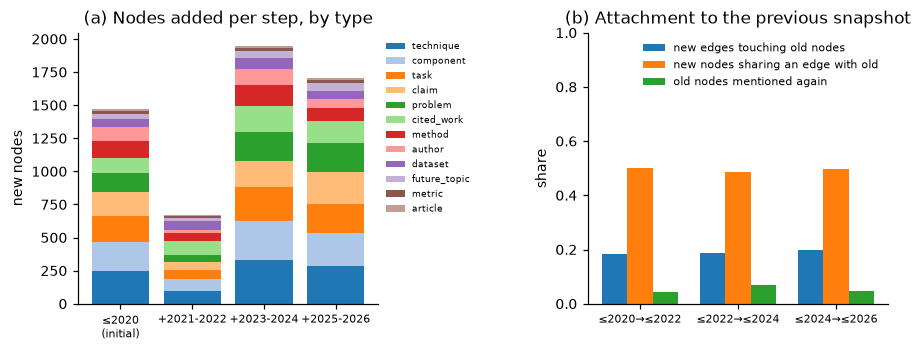

In [22]:
nbt = d.new_nodes_by_type(tkh, snaps)
nbt = nbt.loc[nbt.sum(axis=1).sort_values(ascending=False).index]
steps = [PERIODS[0].replace("<=", "≤") + "\n(initial)"] + ["+" + p for p in PERIODS[1:]]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw={"wspace": 0.7})
bottom = pd.Series(0, index=nbt.columns)
for i, (t, row) in enumerate(nbt.iterrows()):
    ax[0].bar(steps, row, bottom=bottom, color=plt.cm.tab20(i), label=t)
    bottom += row
ax[0].set(ylabel="new nodes", title="(a) Nodes added per step, by type")
ax[0].tick_params(axis="x", labelsize=7)
ax[0].legend(ncol=1, fontsize=6, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")

rates = g[["new_edges_touching_old_nodes", "new_nodes_sharing_edge_with_old", "old_nodes_mentioned_again"]]
names = ["new edges touching old nodes", "new nodes sharing an edge with old", "old nodes mentioned again"]
w = 0.26
for j, (col, name) in enumerate(zip(rates.columns, names)):
    xs = [i + (j - 1) * w for i in range(len(rates))]
    ax[1].bar(xs, rates[col], width=w, label=name, color=f"C{j}")
ax[1].set_xticks(range(len(rates)), [t.replace("<=", "≤").replace(" -> ", "→") for t in rates.index], fontsize=7)
ax[1].set(ylim=(0, 1), ylabel="share", title="(b) Attachment to the previous snapshot")
ax[1].legend(fontsize=7, frameon=False, loc="upper right")
fig.savefig(FIG / "t1_growth_steps.png", bbox_inches="tight"); plt.show()

- **No removals.** Snapshots are strictly cumulative: no node or edge disappears.
- **Thin attachment.** Only about a fifth of new hyper-edges touch any node from the previous snapshot, and fewer than 5% of old nodes are mentioned again. Most growth arrives as new, almost self-contained paper stars.
- **Consequence for T3/T6.** Old nodes will look stable almost by default. Stability should therefore be reported separately for old nodes and for where new papers attach, and compared against a baseline that freezes old assignments.

Shared nodes are the only structural link between papers:

In [23]:
apn = {s.cutoff: d.articles_per_node(tkh, s) for s in snaps}
shared = pd.DataFrame({f"≤{c}": {"nodes in ≥2 articles": int((a >= 2).sum()),
                                  "share single-article": (a == 1).mean()} for c, a in apn.items()})
top = apn[CUTOFFS[-1]].sort_values(ascending=False).head(8)
display(shared)
display(pd.DataFrame({"type": tkh.nodes.loc[top.index, "type"],
                      "surface_form": tkh.nodes.loc[top.index, "surface_form"], "articles": top}))

,≤2020,≤2022,≤2024,≤2026
nodes in ≥2 articles,52.000,134.000,245.00,413.000
share single-article,0.965,0.938,0.94,0.929


,type,surface_form,articles
task_00003,task,materials science,51
task_00010,task,computational chemistry,23
task_00034,task,molecular dynamics,13
task_00033,task,computational physics,13
cite_00048,cited_work,MACE,13
cite_00005,cited_work,SchNet,12
task_00012,task,computational materials science,12
metr_00002,metric,MAE,11


The most shared nodes are generic: 'materials science' appears in 51 of the 52 papers. Such hubs would merge everything in a structure-only clustering, so they need down-weighting in T2.

**Figure 6.3. Growth of cross-paper connectivity.**
- **Layout.** Papers are placed on a circle in publication order, and the positions are fixed across panels. Papers not yet published are shown as grey dots.
- **Links.** A link joins two papers that share at least `MIN_SHARED` nodes. Its width grows with the number of shared nodes, and its colour is the period in which the link first appears, i.e. when the later of the two papers entered.
- **Excluded from links.** Article nodes, and nodes found in more than `HUB_SHARE` of the snapshot's papers: generic hubs such as 'materials science' (51 of 52 papers) or 'computational chemistry' (23).
- **Why the thresholds.** Counting every shared node, almost every pair of papers is linked, because nearly all papers mention a few generic hubs. Even without hubs, many pairs are linked through a single shared node, and the diagram turns into a solid tangle. The table after the figure gives link counts at all three filtering levels, so no links are dropped silently.

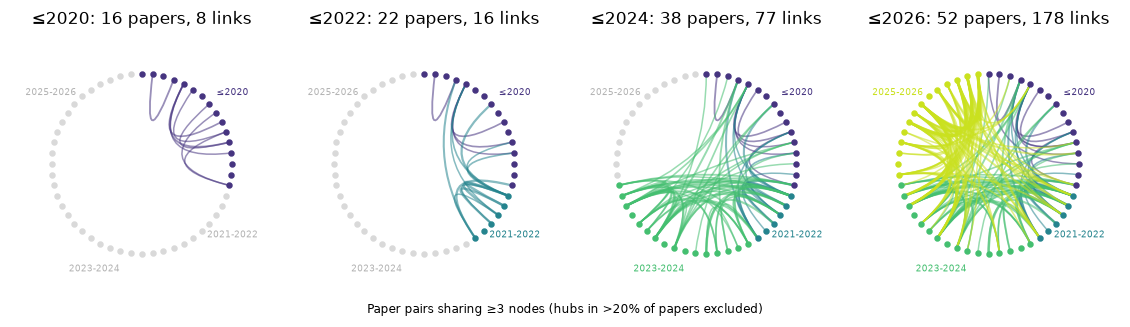

In [24]:
HUB_SHARE, MIN_SHARED = 0.2, 3
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
import math

order = tkh.articles.sort_values("year", kind="stable").index
ang = {a: math.pi / 2 - 2 * math.pi * i / len(order) for i, a in enumerate(order)}
xy = {a: (math.cos(t), math.sin(t)) for a, t in ang.items()}
period_of = {a: PERIODS[next(i for i, c in enumerate(CUTOFFS) if y <= c)] for a, y in tkh.articles["year"].items()}

fig, axes = plt.subplots(1, len(snaps), figsize=(2.6 * len(snaps), 2.9))
for ax, s in zip(axes, snaps):
    links = d.article_links(tkh, s, max_article_share=HUB_SHARE, min_shared=MIN_SHARED)
    late = links.apply(lambda r: max((r.a, r.b), key=lambda a: tkh.articles.at[a, "year"]), axis=1) if len(links) else []
    for (a, b, wgt), la in sorted(zip(links.itertuples(index=False, name=None), late),
                                  key=lambda z: PERIODS.index(period_of[z[1]])):
        path = MPath([xy[a], (0, 0), xy[b]], [MPath.MOVETO, MPath.CURVE3, MPath.CURVE3])
        ax.add_patch(PathPatch(path, fc="none", ec=PCOL[period_of[la]], lw=0.3 + 0.5 * math.log1p(wgt), alpha=0.55))
    for a in order:
        x, y = xy[a]
        ax.plot(x, y, "o", ms=3.2, color=PCOL[period_of[a]] if a in s.articles else "0.85", zorder=3)
    for p in PERIODS:
        arts = [a for a in order if period_of[a] == p]
        t = sum(ang[a] for a in arts) / len(arts)
        ax.text(1.28 * math.cos(t), 1.28 * math.sin(t), p.replace("<=", "≤"), ha="center", va="center",
                fontsize=6, color=PCOL[p] if any(a in s.articles for a in arts) else "0.7")
    ax.set(xlim=(-1.45, 1.45), ylim=(-1.45, 1.45), aspect="equal",
           title=f"≤{s.cutoff}: {len(s.articles)} papers, {len(links)} links")
    ax.axis("off")
fig.suptitle(f"Paper pairs sharing ≥{MIN_SHARED} nodes (hubs in >{HUB_SHARE:.0%} of papers excluded)", fontsize=8, y=0.02)
fig.tight_layout(); fig.savefig(FIG / "t1_article_links.png"); plt.show()

In [25]:
def link_stats(s):
    n, pairs = len(s.articles), len(s.articles) * (len(s.articles) - 1) / 2
    every = d.article_links(tkh, s, max_article_share=1.0, min_shared=1)
    nohub = d.article_links(tkh, s, max_article_share=HUB_SHARE, min_shared=1)
    drawn = nohub[nohub["shared_nodes"] >= MIN_SHARED]
    return {"papers": n,
            "linked pairs (all shared nodes)": len(every), "density (all)": len(every) / pairs,
            f"linked pairs (hubs >{HUB_SHARE:.0%} removed)": len(nohub), "density (no hubs)": len(nohub) / pairs,
            f"drawn: ≥{MIN_SHARED} shared": len(drawn), "density (drawn)": len(drawn) / pairs}

pd.DataFrame({f"≤{s.cutoff}": link_stats(s) for s in snaps})

,≤2020,≤2022,≤2024,≤2026
papers,16.000,22.000,38.000,52.000
linked pairs (all shared nodes),120.000,231.000,666.000,1275.000
density (all),1.000,1.000,0.947,0.962
linked pairs (hubs >20% removed),34.000,77.000,266.000,555.000
density (no hubs),0.283,0.333,0.378,0.419
drawn: ≥3 shared,8.000,16.000,77.000,178.000
density (drawn),0.067,0.069,0.110,0.134


- **Strong overlaps are sparse but growing.** With generic hubs removed, only a minority of paper pairs share three or more nodes: shared methods, cited works, datasets and specific tasks. The share of such pairs rises as the corpus grows.
- **Many strong links reach back.** Recent-period links that end at early papers show new work attaching to the existing graph through a few shared entities. Those are the regions where T3 should expect super-nodes to grow or split, rather than in the untouched remainder.
- **Caveat.** Link counts depend on entity resolution: unmerged near-duplicates and the same name under several node types (§7) hide some real overlap.

## 7. Data-quality problems

In [26]:
q = d.quality_report(tkh)
q

,count,examples,note
check,,,
dangling member ids,0,,
edges with repeated members,0,,
nodes in no hyper-edge,0,,
first_seen_year != earliest provenance year,127,"metr_00002, metr_00004, metr_00005",documented as 'earliest corpus paper'; not use...
edge.year != article_year,154,"h_00344, h_00346, h_00347",not used for snapshots
edge.year > article_year,20,"h_00409, h_00410, h_00411",
member missing the edge's article in provenance,36,"h_00788:meth_00058, h_00789:meth_00058, h_0079...",3 distinct nodes; fixed by the entry-year rule
near-duplicate names within a type (groups),51,"cited_work:ani 1, cited_work:behler parrinello...",52 redundant ids after NFKC/case/punctuation n...
same normalised name under >=2 types,284,"2direct sampling, 3d steerable cnns, ab initio...",


What the checks mean for later tasks:

1. **Referential integrity is clean.** There are no dangling ids, no repeated members and no isolated nodes, so the §6a validator can trust member ids.
2. **Year fields are inconsistent** (§2). The snapshot rule avoids them, and validate.py should check membership against the same rule.
3. **Provenance gaps.** 36 memberships, involving 3 method nodes (NequIP, M3GNet, GNoME), lack the edge's article. The entry-year rule absorbs them.
4. **Entity resolution is incomplete.** No name repeats exactly within a type, but normalising case and punctuation reveals near-duplicates, e.g. 'Tensor Field Networks' / 'TensorField Networks' / 'Tensor-Field Networks'. Many names also recur across types, mostly cited_work vs method: bare 'MACE' exists only as a cited work. Any merging must be logged. The normalised counts depend on the normalisation rule, so they are candidates, not confirmed duplicates.
5. **Character noise.** Non-ASCII hyphens and spaces require NFKC normalisation before any text features are computed.
6. **Extraction coverage varies by paper.** 15 papers lack `cites` and 16 lack `evaluated_on`, which constrains which relations can serve as held-out evaluation signal in T6.
7. **Some type assignments look wrong.** Some dataset nodes are bare element symbols. Some datasets and reviews are typed as `method` (e.g. 'OMat24 dataset'); these were found by inspection and are not counted above.

In [27]:
for check in ["near-duplicate names within a type (groups)", "same normalised name under >=2 types"]:
    print(check, "->", q.at[check, "examples"])

near-duplicate names within a type (groups) -> cited_work:ani 1, cited_work:behler parrinello, cited_work:behler parrinello neural network
same normalised name under >=2 types -> 2direct sampling, 3d steerable cnns, ab initio molecular dynamics


## 8. Verified vs assumed

In [28]:
s0, s1 = summary.iloc[0], summary.iloc[-1]
print(f"Verified (computed above):")
print(f"- {len(snaps)} cumulative snapshots; {int(s0['nodes'])} -> {int(s1['nodes'])} nodes, {int(s0['hyperedges'])} -> {int(s1['hyperedges'])} hyper-edges")
print(f"- 0 closure violations; 0 removals between snapshots")
print(f"- median arity 3, max {int(tkh.edges['arity'].max())}; every edge is a hub-rooted star")
print(f"- {(apn[CUTOFFS[-1]] == 1).mean():.1%} of nodes appear in a single article")
print(f"- new edges touching old nodes: {g['new_edges_touching_old_nodes'].min():.0%}-{g['new_edges_touching_old_nodes'].max():.0%} per transition")

Verified (computed above):
- 4 cumulative snapshots; 1475 -> 5798 nodes, 374 -> 1429 hyper-edges
- 0 closure violations; 0 removals between snapshots
- median arity 3, max 65; every edge is a hub-rooted star
- 92.9% of nodes appear in a single article
- new edges touching old nodes: 18%-20% per transition


**Assumed (not verifiable from the data):**
- `year` is the venue publication year and is the right time axis for P6. Preprint years would move three papers across the 2022/2024 cutoffs.
- Nodes with the same normalised name are *candidate* duplicates, not confirmed ones.
- The ≤2026 snapshot stands for "as of the export" (2026-08-15). The ground truth's "as of Feb 2026" cannot be resolved from integer years.